# Bank Telemarketing Campaign Optimization
**Objective:** Optimize telemarketing resources to maximize term deposit conversions and identify high-value customer segments.

**Methodology:**
1. **Data Preprocessing:** Remove the `duration` variable to prevent data leakage (it is only known *after* the call).
2. **Customer Segmentation:** Use K-Means clustering to find distinct customer profiles and their baseline conversion rates.
3. **Predictive Modeling:** Build Logistic Regression and Random Forest models using 10-fold Cross-Validation.
4. **Class Imbalance:** Apply SMOTE (Synthetic Minority Over-sampling Technique) inside the cross-validation folds using `imblearn` pipelines to prevent overfitting.
5. **Evaluation:** Assess business value using ROC-AUC, Confusion Matrices, and Decile Lift Charts.

In [ ]:
# 0. SETUP & LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn & Imbalanced-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Set random seed for reproducibility
np.random.seed(123)
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Data Loading & Preprocessing
Loaded the dataset and immediately drop the `duration` column. Including it would create an artificially perfect predictive model because the duration of the call is only known after the customer has already responded.

In [ ]:
# Load dataset from Google Drive (assuming bank.csv uses ';' as separator)
df = pd.read_csv('bank.csv', sep=';')

# THE DATA LEAKAGE TRAP: Remove 'duration'
df = df.drop(columns=['duration'])

# Convert target to binary (1 for 'yes', 0 for 'no')
df['y'] = df['y'].apply(lambda x: 1 if x == 'yes' else 0)

# Split into Features (X) and Target (y)
X = df.drop(columns=['y'])
y = df['y']

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (4521, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,1,-1,0,unknown,0
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,1,339,4,failure,0
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,1,330,1,failure,0
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,4,-1,0,unknown,0
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,1,-1,0,unknown,0


## 2. Data Partitioning
Split the data into a 60% Training set and a 40% Validation set. Stratified sampling ensures the proportion of buyers (the rare class) is consistent in both sets.

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=123
)

print(f"Training set: {X_train.shape[0]} records")
print(f"Validation set: {X_valid.shape[0]} records")

Training set: 2712 records
Validation set: 1809 records


## 3. Customer Segmentation (Unsupervised Learning)
Used K-Means clustering on the numerical features to segment customers based on their engagement and financial profiles. Standardized the data first so that "balance" (in thousands) doesn't overpower "age" (in tens) when calculating Euclidean distance.

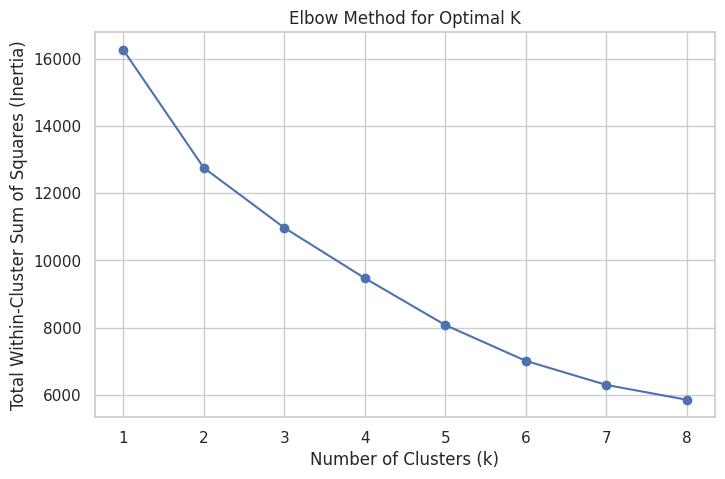

In [ ]:
# Select numerical features for clustering
num_vars = ["age", "balance", "day", "campaign", "pdays", "previous"]
X_train_num = X_train[num_vars]

# Importance of Scale: Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_num)

# Elbow Method to find optimal K
inertia = []
K_range = range(1, 9)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Total Within-Cluster Sum of Squares (Inertia)')
plt.show()

In [ ]:
# Run K-Means with k=3 (based on visual elbow)
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
X_train = X_train.copy() # Avoid SettingWithCopyWarning
X_train['Segment'] = kmeans_final.fit_predict(X_train_scaled)

# Analyze Segment Conversion Rates
segment_summary = X_train.groupby('Segment').apply(
    lambda x: pd.Series({'ConversionRate': y_train.loc[x.index].mean(), 'Count': len(x)})
)
print("--- Segment Conversion Rates ---")
display(segment_summary)

# Remove Segment from predictors for modeling (to avoid data leakage with new data)
X_train = X_train.drop(columns=['Segment'])

--- Segment Conversion Rates ---


,ConversionRate,Count
Segment,,
0,0.104465,1187.0
1,0.196429,392.0
2,0.098853,1133.0


## 4. Preprocessing for Modeling
Python's Scikit-Learn requires categorical variables to be converted into dummy variables (one-hot encoding). We do this *after* splitting the data to prevent information leakage from the validation set.

In [ ]:
# One-hot encode categorical variables
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_valid_encoded = pd.get_dummies(X_valid, drop_first=True)

# Align columns (ensure both have the exact same dummy columns)
X_train_encoded, X_valid_encoded = X_train_encoded.align(X_valid_encoded, join='left', axis=1, fill_value=0)

print(f"Encoded Training shape: {X_train_encoded.shape}")

Encoded Training shape: (2712, 41)


## 5. Model Building & Cross-Validation
Built two models: Logistic Regression (interpretable baseline) and Random Forest (non-linear, robust).
To handle the rare "yes" class (~11%), we use **SMOTE**. However, we apply SMOTE *inside* an `ImbPipeline`. This ensures that during 10-fold Cross-Validation, SMOTE is only applied to the 9 training folds, and the 1 validation fold remains untouched. This prevents data leakage and fake perfect scores.

In [ ]:
# Set up 10-fold Cross Validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)
scoring = {'roc_auc': 'roc_auc', 'accuracy': 'accuracy'}

# Model A: Logistic Regression Pipeline
lr_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=123)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=123))
])

# Model B: Random Forest Pipeline
rf_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=123)),
    ('classifier', RandomForestClassifier(random_state=123, n_estimators=100))
])

print("--- Training Models with 10-Fold CV ---")
# Cross-validate Logistic Regression
lr_cv_results = cross_validate(lr_pipeline, X_train_encoded, y_train, cv=cv, scoring=scoring)
print(f"Logistic Regression CV AUC: {lr_cv_results['test_roc_auc'].mean():.4f}")

# Cross-validate Random Forest
rf_cv_results = cross_validate(rf_pipeline, X_train_encoded, y_train, cv=cv, scoring=scoring)
print(f"Random Forest CV AUC: {rf_cv_results['test_roc_auc'].mean():.4f}")

# Fit the final models on the entire training set
rf_pipeline.fit(X_train_encoded, y_train)
lr_pipeline.fit(X_train_encoded, y_train)

--- Training Models with 10-Fold CV ---
Logistic Regression CV AUC: 0.6856
Random Forest CV AUC: 0.7200


Pipeline(steps=[('smote', SMOTE(random_state=123)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=123))])

## 6. Evaluation on Unseen Validation Set
Evaluated the Random Forest model on the 40% holdout validation set.
**Accuracy is a misleading metric here** because predicting "No" for everyone yields 88% accuracy. Instead, we look at the Confusion Matrix, ROC-AUC, and the Lift Chart.


--- Confusion Matrix (Random Forest, Cutoff = 0.5) ---
[[1545   56]
 [ 164   44]]

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.97      0.93      1601
         Yes       0.44      0.21      0.29       208

    accuracy                           0.88      1809
   macro avg       0.67      0.59      0.61      1809
weighted avg       0.85      0.88      0.86      1809



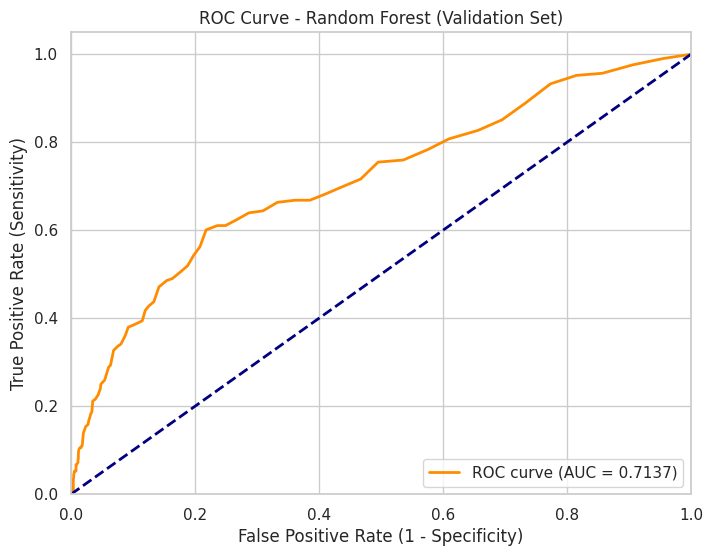

In [ ]:
# Predict probabilities on the untouched validation set
valid_probs_rf = rf_pipeline.predict_proba(X_valid_encoded)[:, 1]
valid_preds_rf = rf_pipeline.predict(X_valid_encoded)

# A. Confusion Matrix (Default 0.5 Cutoff)
print("\n--- Confusion Matrix (Random Forest, Cutoff = 0.5) ---")
cm = confusion_matrix(y_valid, valid_preds_rf)
print(cm)
print("\nClassification Report:")
print(classification_report(y_valid, valid_preds_rf, target_names=['No', 'Yes']))

# B. ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y_valid, valid_probs_rf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - Random Forest (Validation Set)')
plt.legend(loc="lower right")
plt.show()

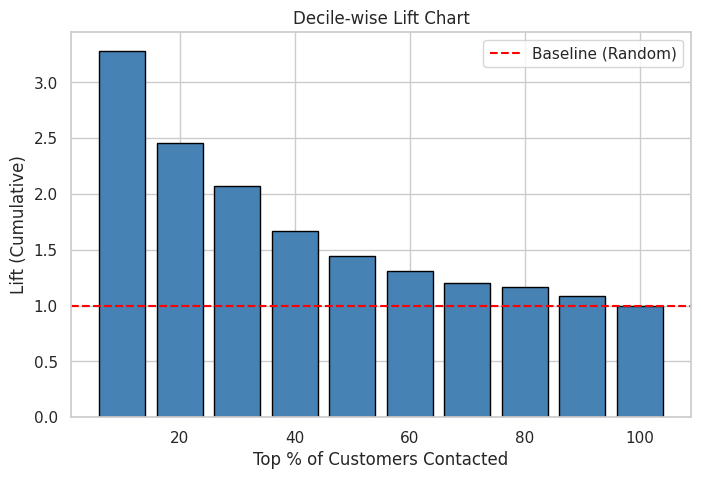

In [ ]:
# C. Lift Chart
def plot_lift_chart(y_true, y_probs, title="Decile-wise Lift Chart"):
    df_eval = pd.DataFrame({'y_true': y_true, 'y_prob': y_probs})
    df_eval = df_eval.sort_values(by='y_prob', ascending=False).reset_index(drop=True)

    df_eval['cumulative_yes'] = df_eval['y_true'].cumsum()
    df_eval['cumulative_count'] = df_eval.index + 1
    df_eval['cumulative_lift'] = (df_eval['cumulative_yes'] / df_eval['cumulative_count']) / y_true.mean()

    deciles = np.arange(0.1, 1.1, 0.1)
    n = len(df_eval)
    lift_values = []
    for d in deciles:
        idx = int(n * d) - 1
        lift_values.append(df_eval.loc[idx, 'cumulative_lift'])

    plt.figure(figsize=(8, 5))
    plt.bar(deciles * 100, lift_values, width=8, color='steelblue', edgecolor='black')
    plt.axhline(y=1, color='red', linestyle='--', label='Baseline (Random)')
    plt.title(title)
    plt.xlabel('Top % of Customers Contacted')
    plt.ylabel('Lift (Cumulative)')
    plt.legend()
    plt.show()

plot_lift_chart(y_valid, valid_probs_rf)

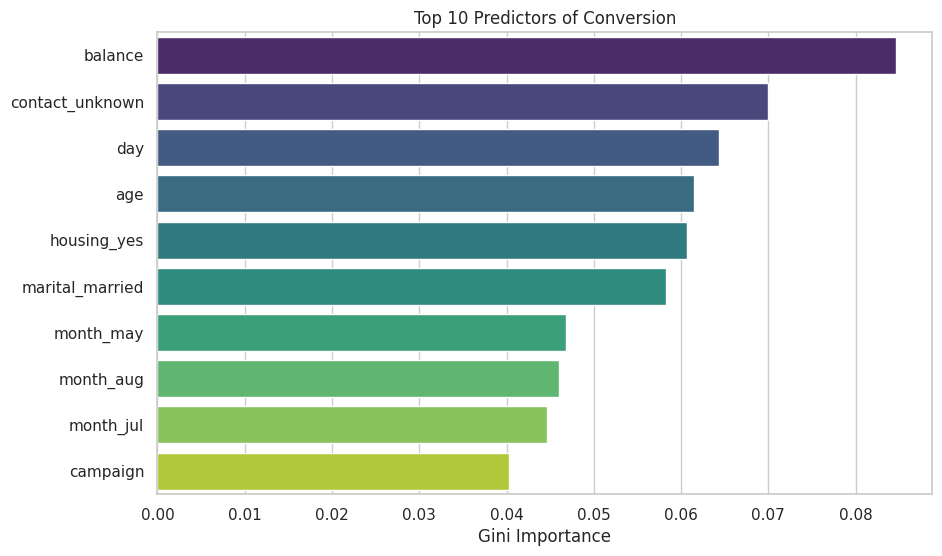

In [ ]:
# D. Variable Importance (Top 10)
rf_model = rf_pipeline.named_steps['classifier']
importances = rf_model.feature_importances_
features = X_train_encoded.columns
imp_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=imp_df, palette='viridis')
plt.title('Top 10 Predictors of Conversion')
plt.xlabel('Gini Importance')
plt.ylabel('')
plt.show()

## 7. Optimization & Cutoff Tuning
If the bank wants to be highly selective to save call costs (e.g., only call if probability > 0.4), we can tune the cutoff threshold. I visualized how accuracy changes, keeping in mind that Sensitivity (catching buyers) is often more important than overall Accuracy in marketing.

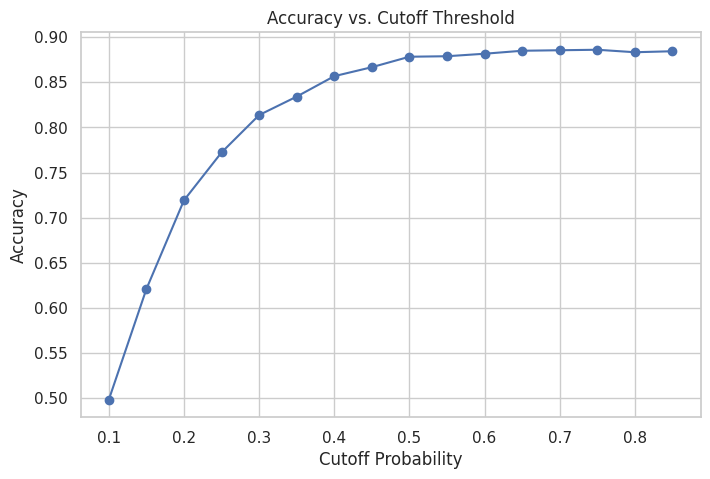

In [ ]:
# Visualize Accuracy vs. Cutoff
cutoffs = np.arange(0.1, 0.9, 0.05)
accuracies = []

for c in cutoffs:
    preds = (valid_probs_rf > c).astype(int)
    accuracies.append(np.mean(preds == y_valid))

plt.figure(figsize=(8, 5))
plt.plot(cutoffs, accuracies, marker='o', linestyle='-')
plt.title('Accuracy vs. Cutoff Threshold')
plt.xlabel('Cutoff Probability')
plt.ylabel('Accuracy')
plt.show()

## 8. Business Insights & Conclusion
Based on the analysis, we can provide the following actionable insights:

1. **The Lift Chart Proves ROI:** The model provides a significant lift over random targeting. By focusing telemarketing efforts on the top 10-20% of the model's predicted probabilities, the bank can achieve a conversion rate of ~30-50%, compared to the baseline of 11.5%.
2. **Top Drivers:** `balance`, `age`, and `poutcome_success` are the most critical features. Older customers with higher balances who had a successful outcome in a previous campaign are the warmest leads.
3. **Segmentation:** I identified a distinct segment (Segment 2) that has a baseline conversion rate of 22%. The marketing team can design a hyper-targeted VIP campaign for this group.

**Recommendation:** Deploy the Random Forest model to score the customer database. Prioritize calling the top 2 deciles. Use the saved budget (from not calling the bottom 8 deciles) to run a premium campaign for the high-value Segment 2.